# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
warnings.filterwarnings('ignore')

# Reading of Data

In [2]:
df=pd.read_csv("C:\\Users\\Devesh\\Downloads\\1183_Final_Dataset.csv")

In [3]:
df.head(20)

,Unnamed: 0,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR,PFSCR,AEPT,AECONT,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0
0,0,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
1,1,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,Y,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
2,2,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
3,3,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
4,4,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,55.0,Y,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
5,5,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,55.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
6,6,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,28.0,Liver,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
7,7,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,28.0,Liver,N,55.0,Y,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
8,8,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,28.0,Liver,N,55.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
9,9,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,30.0,Liver,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0


In [4]:
adsl = pd.read_csv("C:\\Users\\Devesh\\Downloads\\ML_kolate\\NCT00364013 - 1183-20240715T034329Z-001\\NCT00364013 - 1183\\NCT00364013 - 1183 (csv)\\adsl_pds2019.csv")

In [5]:
adsl.isnull().sum()

SUBJID       0
TRT          0
ATRT         0
PRSURG       0
DTHDY        0
DTH          0
PFSDYCR      0
PFSCR        0
LIVERMET     0
DIAGMONS    11
AGE          0
SEX          0
B_WEIGHT     0
B_HEIGHT     1
RACE         0
B_ECOG       1
HISSUBTY     2
B_METANM     3
DIAGTYPE     0
dtype: int64

In [6]:
df = pd.merge(df,adsl,on=['SUBJID'],how='left')

In [7]:
dftl = df[df['LSCAT']=='Target lesion']

In [8]:
dftl.head()

,Unnamed: 0,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR_x,PFSCR_x,AEPT,AECONT,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0,TRT,ATRT,PRSURG,DTHDY,DTH,PFSDYCR_y,PFSCR_y,LIVERMET,DIAGMONS,AGE,SEX,B_WEIGHT,B_HEIGHT,RACE,B_ECOG,HISSUBTY,B_METANM,DIAGTYPE
0,0,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,Male,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon
1,1,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,Y,54.0,1.0,Dermatitis acneiform,N,2,0,0,0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,Male,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon
2,2,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,Male,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon
3,3,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,Male,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon
4,4,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,55.0,Y,54.0,1.0,Dermatitis acneiform,N,2,0,0,0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,Male,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon


In [9]:
def calculate_percentage_change(group):
    max_lssld = group['LSSLD'].max()
    min_lssld = group['LSSLD'].min()
    if max_lssld != 0:
        group['LSSLD_PCT_CHANGE'] = 100 * (max_lssld - min_lssld) / max_lssld
    else:
        group['LSSLD_PCT_CHANGE'] = 0
    return group.iloc[[0]].drop(columns=['LSSLD'])

In [10]:
# Group by SUBJID and LSSITE, then apply the percentage change calculation
result_df = dftl.groupby(['SUBJID', 'LSSITE']).apply(calculate_percentage_change).reset_index(drop=True)

In [11]:
result_df.head() 

,Unnamed: 0,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSLD,LSSITE,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR_x,PFSCR_x,AEPT,AECONT,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0,TRT,ATRT,PRSURG,DTHDY,DTH,PFSDYCR_y,PFSCR_y,LIVERMET,DIAGMONS,AGE,SEX,B_WEIGHT,B_HEIGHT,RACE,B_ECOG,HISSUBTY,B_METANM,DIAGTYPE,LSSLD_PCT_CHANGE
0,0,3,Albumin,N,36.840000,-11.0,Target lesion,N,39.0,Liver,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,Male,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon,44.915254
1,12,3,Albumin,N,36.840000,-11.0,Target lesion,N,51.0,Other,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,Male,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon,6.779661
2,1029,7,Albumin,N,29.666667,-14.0,Target lesion,N,82.0,Liver,N,-14.0,N,339.0,1.0,Folliculitis,N,0,1,1,0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,339.0,1.0,339.0,1.0,Y,2.786885,52.0,Female,53.0,160.0,Hispanic or Latino,Symptoms but ambulatory,Mucinous,3.0,Colon,76.347826
3,1008,7,Albumin,N,29.666667,-14.0,Target lesion,N,27.0,Lymph Nodes,N,-14.0,N,339.0,1.0,Folliculitis,N,0,1,1,0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,339.0,1.0,339.0,1.0,Y,2.786885,52.0,Female,53.0,160.0,Hispanic or Latino,Symptoms but ambulatory,Mucinous,3.0,Colon,62.260870
4,34944,9,Albumin,N,44.285714,-2.0,Target lesion,N,43.0,Lymph Nodes,N,-2.0,N,301.0,1.0,Dermatitis acneiform,N,1,0,0,0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,696.0,1.0,301.0,1.0,Y,75.704918,42.0,Female,69.0,148.0,Hispanic or Latino,Fully active,No sub-type,4.0,Colon,64.705882


In [12]:
result_df= result_df.drop(columns=['Unnamed: 0','AEPT', 'AECONT', 'Severity_1.0', 'Severity_2.0','Severity_3.0', 'Severity_4.0'])

In [13]:
result_df.shape

(445, 33)

In [14]:
result_df.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSLD,LSSITE,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR_x,PFSCR_x,TRT,ATRT,PRSURG,DTHDY,DTH,PFSDYCR_y,PFSCR_y,LIVERMET,DIAGMONS,AGE,SEX,B_WEIGHT,B_HEIGHT,RACE,B_ECOG,HISSUBTY,B_METANM,DIAGTYPE,LSSLD_PCT_CHANGE
0,3,Albumin,N,36.840000,-11.0,Target lesion,N,39.0,Liver,N,-11.0,N,54.0,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,Male,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon,44.915254
1,3,Albumin,N,36.840000,-11.0,Target lesion,N,51.0,Other,N,-11.0,N,54.0,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,Male,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon,6.779661
2,7,Albumin,N,29.666667,-14.0,Target lesion,N,82.0,Liver,N,-14.0,N,339.0,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,339.0,1.0,339.0,1.0,Y,2.786885,52.0,Female,53.0,160.0,Hispanic or Latino,Symptoms but ambulatory,Mucinous,3.0,Colon,76.347826
3,7,Albumin,N,29.666667,-14.0,Target lesion,N,27.0,Lymph Nodes,N,-14.0,N,339.0,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,339.0,1.0,339.0,1.0,Y,2.786885,52.0,Female,53.0,160.0,Hispanic or Latino,Symptoms but ambulatory,Mucinous,3.0,Colon,62.260870
4,9,Albumin,N,44.285714,-2.0,Target lesion,N,43.0,Lymph Nodes,N,-2.0,N,301.0,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,696.0,1.0,301.0,1.0,Y,75.704918,42.0,Female,69.0,148.0,Hispanic or Latino,Fully active,No sub-type,4.0,Colon,64.705882


In [15]:
result_df = result_df.drop_duplicates(keep='first')

In [16]:
result_df.shape

(445, 33)

In [17]:
result_df['LSSLD_Change'] = np.where(result_df['LSSLD_PCT_CHANGE'] > 30, 1, 0)

In [18]:
result_df['LSSLD_Change'].value_counts()

1    334
0    111
Name: LSSLD_Change, dtype: int64

In [19]:
numerical_columns = ['LBSTRESN', 'VISITDY_x', 'LSSLD', 'LSLD', 'VISITDY_y', 'PFSDYCR', 'PFSCR','DIAGMONS','AGE','B_WEIGHT','B_HEIGHT']
binary_columns = ['LBBASE','LBTEST','LSSITE','SEX','RACE','B_ECOG','HISSUBTY','DIAGTYPE','LIVERMET','PRSURG']

In [20]:
df_encoded = pd.get_dummies(result_df, columns=binary_columns, drop_first=True, prefix_sep='_')

In [21]:
df_encoded.head()

,SUBJID,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSLD,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR_x,PFSCR_x,TRT,ATRT,DTHDY,DTH,PFSDYCR_y,PFSCR_y,DIAGMONS,AGE,B_WEIGHT,B_HEIGHT,B_METANM,LSSLD_PCT_CHANGE,LSSLD_Change,LSSITE_Bone,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Spleen,SEX_Male,RACE_Black or African American,RACE_Hispanic or Latino,RACE_Other,RACE_White or Caucasian,B_ECOG_In bed less than 50% of the time,B_ECOG_Symptoms but ambulatory,HISSUBTY_No sub-type,HISSUBTY_Other,HISSUBTY_Unknown,DIAGTYPE_Rectal,LIVERMET_Y,PRSURG_Y
0,3,36.840000,-11.0,Target lesion,N,39.0,N,-11.0,N,54.0,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,301.0,1.0,54.0,1.0,1.868852,65.0,67.0,165.0,5.0,44.915254,1,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,1,0,0,0,1,1
1,3,36.840000,-11.0,Target lesion,N,51.0,N,-11.0,N,54.0,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,301.0,1.0,54.0,1.0,1.868852,65.0,67.0,165.0,5.0,6.779661,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,1,1,0,0,0,1,1
2,7,29.666667,-14.0,Target lesion,N,82.0,N,-14.0,N,339.0,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,339.0,1.0,339.0,1.0,2.786885,52.0,53.0,160.0,3.0,76.347826,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,1
3,7,29.666667,-14.0,Target lesion,N,27.0,N,-14.0,N,339.0,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,339.0,1.0,339.0,1.0,2.786885,52.0,53.0,160.0,3.0,62.260870,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,1
4,9,44.285714,-2.0,Target lesion,N,43.0,N,-2.0,N,301.0,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,696.0,1.0,301.0,1.0,75.704918,42.0,69.0,148.0,4.0,64.705882,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,1


In [22]:
df_encoded.drop(columns=["LSCAT","VISITDY_x","VISITDY_y","RSNEW","LSSLD_PCT_CHANGE","LSNEW","LSNEWANY","TRT","ATRT"],inplace=True)

In [23]:
df_encoded.shape

(445, 37)

In [24]:
df_encoded = df_encoded.dropna()

In [25]:
df_encoded.head()

,SUBJID,LBSTRESN,LSLD,PFSDYCR_x,PFSCR_x,DTHDY,DTH,PFSDYCR_y,PFSCR_y,DIAGMONS,AGE,B_WEIGHT,B_HEIGHT,B_METANM,LSSLD_Change,LSSITE_Bone,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Spleen,SEX_Male,RACE_Black or African American,RACE_Hispanic or Latino,RACE_Other,RACE_White or Caucasian,B_ECOG_In bed less than 50% of the time,B_ECOG_Symptoms but ambulatory,HISSUBTY_No sub-type,HISSUBTY_Other,HISSUBTY_Unknown,DIAGTYPE_Rectal,LIVERMET_Y,PRSURG_Y
0,3,36.840000,39.0,54.0,1.0,301.0,1.0,54.0,1.0,1.868852,65.0,67.0,165.0,5.0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,1,0,0,0,1,1
1,3,36.840000,51.0,54.0,1.0,301.0,1.0,54.0,1.0,1.868852,65.0,67.0,165.0,5.0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,1,1,0,0,0,1,1
2,7,29.666667,82.0,339.0,1.0,339.0,1.0,339.0,1.0,2.786885,52.0,53.0,160.0,3.0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,1
3,7,29.666667,27.0,339.0,1.0,339.0,1.0,339.0,1.0,2.786885,52.0,53.0,160.0,3.0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,1
4,9,44.285714,43.0,301.0,1.0,696.0,1.0,301.0,1.0,75.704918,42.0,69.0,148.0,4.0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,1


 # Partial Objective Responce 1183

In [26]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

In [27]:



X = df_encoded.drop('LSSLD_Change', axis=1)
y = df_encoded['LSSLD_Change']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [28]:
param_grids = {
    'Logistic Regression': {
        'C': [0.001, 0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear']  # 'liblinear' for both l1 and l2 penalties
    },
    'Random Forest': {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5],
        'min_samples_leaf': [1, 2]
    },
    'SVM': {
        'C': [0.1, 1, 10],
        'kernel': ['rbf', 'linear'],
        'gamma': ['scale', 'auto']
    },
    'XGBoost': {
        'n_estimators': [50, 100, 200],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.1, 0.3],
        'subsample': [0.8, 0.99],
        'colsample_bytree': [0.8, 0.99]
    }
}

In [29]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(random_state=42),
    'XGBoost': XGBClassifier(random_state=42)
}

In [30]:
for name, model in models.items():
    print(f"Tuning {name}...")
    grid_search = GridSearchCV(estimator=model, param_grid=param_grids[name], 
                               cv=5, n_jobs=-1, verbose=1, scoring='accuracy')
    grid_search.fit(X_train_scaled, y_train)
    
    print(f"Best parameters for {name}: {grid_search.best_params_}")
    print(f"Best cross-validation score: {grid_search.best_score_:.4f}")
    
    # Use the best model to make predictions
    best_model = grid_search.best_estimator_
    y_pred = best_model.predict(X_test_scaled)
    
    # Evaluate
    print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("\n")

Tuning Logistic Regression...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters for Logistic Regression: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Best cross-validation score: 0.7776
Test Accuracy: 0.7816
Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.44      0.46        18
           1       0.86      0.87      0.86        69

    accuracy                           0.78        87
   macro avg       0.66      0.66      0.66        87
weighted avg       0.78      0.78      0.78        87



Tuning Random Forest...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters for Random Forest: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best cross-validation score: 0.8266
Test Accuracy: 0.8506
Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.67      0.65        18
        

In [31]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[11  7]
 [ 4 65]]


In [32]:
feature_importance_ae = pd.DataFrame({'feature': X.columns, 'importance': best_model.feature_importances_})
feature_importance_ae = feature_importance_ae.sort_values('importance', ascending=False)

print("Top features for pe_tl:")
print(feature_importance_ae.head(20))

Top features for pe_tl:
                                    feature  importance
31                           HISSUBTY_Other    0.097457
17                             LSSITE_Liver    0.075650
6                                       DTH    0.064909
3                                 PFSDYCR_x    0.063739
13                                 B_METANM    0.056895
27                  RACE_White or Caucasian    0.052621
5                                     DTHDY    0.051069
7                                 PFSDYCR_y    0.044243
28  B_ECOG_In bed less than 50% of the time    0.040159
12                                 B_HEIGHT    0.039635
1                                  LBSTRESN    0.039586
34                               LIVERMET_Y    0.039284
11                                 B_WEIGHT    0.037145
0                                    SUBJID    0.036976
9                                  DIAGMONS    0.035594
23                                 SEX_Male    0.034357
29           B_ECOG_Symp

In [ ]:
# class_report = classification_report(y_test, y_pred)
# print("Classification Report:")
# print(class_report)

# data load for 1186

In [33]:
df1=pd.read_csv("C:\\Users\Devesh\\kolate_ml_predictionEngine\\prediction_engine\\Combined_model\\llsld_1186.csv")

In [34]:
df1 = df1.drop_duplicates(keep='first')

In [35]:
df1.shape

(3996, 75)

In [36]:
df1.columns

Index(['SUBJID', 'DOSREFDY', 'LSTYPE', 'LSCAT', 'ENRREFDY', 'LSNEWANY', 'LSSLDPCH', 'LSSLDPCN', 'LSRI', 'LSSITE', 'AGE_x', 'SEXCD_x', 'TRTDOSE_x', 'ATRT', 'PRBEVCD', 'PROXACDR', 'PROXAM', 'PFSCR', 'PFSCRV', 'PDLR', 'TRTDUR', 'B_METANM', 'KRAS', 'TUMCAT', 'LIVRONLY_x', 'PFSCR.1', 'PDLR.1', 'B_ALPNM', 'B_CEA', 'B_CREAT', 'CDOSE_x', 'IRCDOSE', 'FBDUR', 'FBCDOSE', 'FIDUR', 'FICDOSE', 'DIAGMONS_x', 'METMONS', 'BIOPTPCT', 'BIOPRS', 'CDOSE_y', 'DSDLYPC', 'CHDLYNM', 'CHDLYPC', 'PROPDOSE', 'AGE_y', 'SEXCD_y', 'LIVRONLY_y', 'TRTDOSE_y', 'CHRESPCD', 'CHDRSNCD', 'CHTERM_5 FU', 'CHTERM_5-FU', 'CHTERM_CAPECITABINE', 'CHTERM_LEUCOVORIN', 'CHTERM_OXALIPLATIN', 'CHANY_Y', 'DTCAUSCD', 'DIAGMONS_y', 'BIOPACPT', 'BIOPCYTO', 'PFUP', 'KRASCD', 'EVALITT_Y', 'EXDURMN', 'ACTTRTCD', 'DOSE', 'LBSTRESN', 'LBSTNRLO', 'LBSTNRHI', 'LBORRESN', 'LBBLRES', 'LBBASE_N', 'LBBASE_Y', 'LSSLD_PCT_CHANGE'], dtype='object')

In [37]:
df1.head()

,SUBJID,DOSREFDY,LSTYPE,LSCAT,ENRREFDY,LSNEWANY,LSSLDPCH,LSSLDPCN,LSRI,LSSITE,AGE_x,SEXCD_x,TRTDOSE_x,ATRT,PRBEVCD,PROXACDR,PROXAM,PFSCR,PFSCRV,PDLR,TRTDUR,B_METANM,KRAS,TUMCAT,LIVRONLY_x,PFSCR.1,PDLR.1,B_ALPNM,B_CEA,B_CREAT,CDOSE_x,IRCDOSE,FBDUR,FBCDOSE,FIDUR,FICDOSE,DIAGMONS_x,METMONS,BIOPTPCT,BIOPRS,CDOSE_y,DSDLYPC,CHDLYNM,CHDLYPC,PROPDOSE,AGE_y,SEXCD_y,LIVRONLY_y,TRTDOSE_y,CHRESPCD,CHDRSNCD,CHTERM_5 FU,CHTERM_5-FU,CHTERM_CAPECITABINE,CHTERM_LEUCOVORIN,CHTERM_OXALIPLATIN,CHANY_Y,DTCAUSCD,DIAGMONS_y,BIOPACPT,BIOPCYTO,PFUP,KRASCD,EVALITT_Y,EXDURMN,ACTTRTCD,DOSE,LBSTRESN,LBSTNRLO,LBSTNRHI,LBORRESN,LBBLRES,LBBASE_N,LBBASE_Y,LSSLD_PCT_CHANGE
0,201001001,106.0,Central,New lesion,108.0,Y,-19.0,-19.0,4.0,Bone,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,1.0,1.0,219.0,4.0,Mutant,Y,N,1.0,1.0,106.0,17.5,97.24,7680.0,5804.98,230.0,12900.05,230.0,77418.0,9.540984,9.540984,61.28,Positive,7680.0,0.0625,1.0,0.0625,3.041537,54.0,M,N,6.0,4.0,7.0,0.0,1.0,0.0,0.0,1.0,1.0,7.0,9.540984,Y,2.1,202.0,2.0,1,601.7,64.2,1458.689875,53.119213,35.280165,75.074683,41.818998,56.476435,1,1,NaN
1,201001001,-15.0,Central,Target lesion,-13.0,N,NaN,NaN,4.0,Liver,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,1.0,1.0,219.0,4.0,Mutant,Y,N,1.0,1.0,106.0,17.5,97.24,7680.0,5804.98,230.0,12900.05,230.0,77418.0,9.540984,9.540984,61.28,Positive,7680.0,0.0625,1.0,0.0625,3.041537,54.0,M,N,6.0,4.0,7.0,0.0,1.0,0.0,0.0,1.0,1.0,7.0,9.540984,Y,2.1,202.0,2.0,1,601.7,64.2,1458.689875,53.119213,35.280165,75.074683,41.818998,56.476435,1,1,78.289474
2,201001001,-15.0,Local,Target lesion,-13.0,NaN,NaN,NaN,NaN,Lung parenchyma,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,1.0,1.0,219.0,4.0,Mutant,Y,N,1.0,1.0,106.0,17.5,97.24,7680.0,5804.98,230.0,12900.05,230.0,77418.0,9.540984,9.540984,61.28,Positive,7680.0,0.0625,1.0,0.0625,3.041537,54.0,M,N,6.0,4.0,7.0,0.0,1.0,0.0,0.0,1.0,1.0,7.0,9.540984,Y,2.1,202.0,2.0,1,601.7,64.2,1458.689875,53.119213,35.280165,75.074683,41.818998,56.476435,1,1,27.966102
3,201001001,-15.0,Central,Non-target lesion,-13.0,N,NaN,NaN,4.0,Lymph Nodes,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,1.0,1.0,219.0,4.0,Mutant,Y,N,1.0,1.0,106.0,17.5,97.24,7680.0,5804.98,230.0,12900.05,230.0,77418.0,9.540984,9.540984,61.28,Positive,7680.0,0.0625,1.0,0.0625,3.041537,54.0,M,N,6.0,4.0,7.0,0.0,1.0,0.0,0.0,1.0,1.0,7.0,9.540984,Y,2.1,202.0,2.0,1,601.7,64.2,1458.689875,53.119213,35.280165,75.074683,41.818998,56.476435,1,1,NaN
4,201001001,-15.0,Central,Target lesion,-13.0,N,NaN,NaN,4.0,Pulmonary,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,1.0,1.0,219.0,4.0,Mutant,Y,N,1.0,1.0,106.0,17.5,97.24,7680.0,5804.98,230.0,12900.05,230.0,77418.0,9.540984,9.540984,61.28,Positive,7680.0,0.0625,1.0,0.0625,3.041537,54.0,M,N,6.0,4.0,7.0,0.0,1.0,0.0,0.0,1.0,1.0,7.0,9.540984,Y,2.1,202.0,2.0,1,601.7,64.2,1458.689875,53.119213,35.280165,75.074683,41.818998,56.476435,1,1,78.289474


In [38]:
dfntl_1186 = df1[df1['LSCAT']=='Non-target lesion']

In [39]:
dfntl_1186.to_csv('1186_ntl.csv', index=False)

In [40]:
dfntl_1186.shape

(1951, 75)

In [41]:
new_names = {'SEXCD_x': 'SEX', 'AGE_x': 'AGE'}

# rename the columns
df1 = df1.rename(columns=new_names)

In [42]:
df1 = df1[df1['LSCAT']=='Target lesion']

In [43]:
null_count=df1.isnull().sum()

In [44]:
df1.drop(columns=["LSCAT","ATRT"],inplace=True)

In [45]:
features_to_drop = null_count[null_count > 500].index
df1_cleaned = df1.drop(columns=features_to_drop)
df1 = df1_cleaned.fillna(df1_cleaned.mean())

In [46]:
df1 = pd.get_dummies(df1, drop_first=True)

In [47]:
df1.shape

(1950, 90)

In [37]:
#df1.drop(columns=["Unnamed: 0","min_LSSLD","RSNEW_N", "RSNEW_Y","max_DOSREFDY", "max_LSSLD", "LSSLD_Diff", "Percentage_LSSLD_Change","ATRT"],inplace=True)

In [48]:
df1 = df1.drop_duplicates(keep='first')

In [49]:
df1['LSSLD_Change'] = np.where(df1['LSSLD_PCT_CHANGE'] > 30, 1, 0)

In [50]:
df1['LSSLD_Change'].value_counts()

1    1184
0     766
Name: LSSLD_Change, dtype: int64

In [51]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

In [52]:
df1.head()

,SUBJID,DOSREFDY,ENRREFDY,AGE,PRBEVCD,PROXACDR,PFSCR,PFSCRV,PDLR,TRTDUR,B_METANM,PFSCR.1,PDLR.1,B_ALPNM,B_CEA,B_CREAT,IRCDOSE,FBDUR,FBCDOSE,FIDUR,FICDOSE,DIAGMONS_x,METMONS,BIOPTPCT,AGE_y,CHRESPCD,CHDRSNCD,CHTERM_5 FU,CHTERM_5-FU,CHTERM_CAPECITABINE,CHTERM_LEUCOVORIN,CHTERM_OXALIPLATIN,CHANY_Y,DTCAUSCD,DIAGMONS_y,PFUP,KRASCD,EVALITT_Y,EXDURMN,ACTTRTCD,DOSE,LBSTRESN,LBSTNRLO,LBSTNRHI,LBORRESN,LBBLRES,LBBASE_N,LBBASE_Y,LSSLD_PCT_CHANGE,LSTYPE_Local,LSSITE_Adrenal gland,LSSITE_Ascites,LSSITE_Bone,LSSITE_Breast,LSSITE_Chest,LSSITE_Chest wall,LSSITE_Colon,LSSITE_Gastrointestinal,LSSITE_Genitourinary/Reproductive,LSSITE_Heart,LSSITE_Kidney,LSSITE_Liver,LSSITE_Lung parenchyma,LSSITE_Lymph Nodes,LSSITE_Other,LSSITE_Pancreas,LSSITE_Pelvic Site,LSSITE_Pelvis,LSSITE_Peritoneum,LSSITE_Pharynx,LSSITE_Pleura or pleural wall,LSSITE_Pulmonary,LSSITE_Rectum,LSSITE_Retroperitoneum,LSSITE_Skin,LSSITE_Small Intestine,LSSITE_Spinal cord,LSSITE_Spleen,LSSITE_Stomach,SEX_M,PROXAM_Y,KRAS_Mutant,KRAS_Wild-type,TUMCAT_Y,LIVRONLY_x_Y,BIOPRS_Negative,BIOPRS_Positive,SEXCD_y_M,LIVRONLY_y_Y,BIOPACPT_Y,LSSLD_Change
1,201001001,-15.0,-13.0,54.0,1.0,1.0,1.0,1.0,1.0,219.0,4.0,1.0,1.0,106.0,17.5,97.240,5804.98,230.0,12900.05,230.0,77418.00,9.540984,9.540984,61.28,54.0,4.0,7.0,0.0,1.0,0.0,0.0,1.0,1.0,7.0,9.540984,202.0,2.0,1,601.70,64.2,1458.689875,53.119213,35.280165,75.074683,41.818998,56.476435,1,1,78.289474,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,0,1,1,0,1,1
2,201001001,-15.0,-13.0,54.0,1.0,1.0,1.0,1.0,1.0,219.0,4.0,1.0,1.0,106.0,17.5,97.240,5804.98,230.0,12900.05,230.0,77418.00,9.540984,9.540984,61.28,54.0,4.0,7.0,0.0,1.0,0.0,0.0,1.0,1.0,7.0,9.540984,202.0,2.0,1,601.70,64.2,1458.689875,53.119213,35.280165,75.074683,41.818998,56.476435,1,1,27.966102,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,0,1,1,0,1,0
4,201001001,-15.0,-13.0,54.0,1.0,1.0,1.0,1.0,1.0,219.0,4.0,1.0,1.0,106.0,17.5,97.240,5804.98,230.0,12900.05,230.0,77418.00,9.540984,9.540984,61.28,54.0,4.0,7.0,0.0,1.0,0.0,0.0,1.0,1.0,7.0,9.540984,202.0,2.0,1,601.70,64.2,1458.689875,53.119213,35.280165,75.074683,41.818998,56.476435,1,1,78.289474,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,1,0,0,1,1,0,1,1
5,201001001,-15.0,-13.0,54.0,1.0,1.0,1.0,1.0,1.0,219.0,4.0,1.0,1.0,106.0,17.5,97.240,5804.98,230.0,12900.05,230.0,77418.00,9.540984,9.540984,61.28,54.0,4.0,7.0,0.0,1.0,0.0,0.0,1.0,1.0,7.0,9.540984,202.0,2.0,1,601.70,64.2,1458.689875,53.119213,35.280165,75.074683,41.818998,56.476435,1,1,44.078947,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,1,0,0,1,1,0,1,1
6,201001002,-18.0,-12.0,66.0,1.0,1.0,1.0,1.0,1.0,60.0,3.0,1.0,1.0,173.0,18.1,87.516,1900.20,71.0,4222.70,71.0,25341.69,6.131148,6.131148,43.22,66.0,5.0,7.0,0.0,0.0,1.0,0.0,1.0,1.0,7.0,6.131148,200.0,2.0,1,601.68,64.2,1539.070000,64.343600,35.105329,74.729192,53.325578,64.164232,1,1,64.383562,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,0,1,1,0,1,1


In [53]:
df1.drop(columns=['TRTDUR','LSSLD_PCT_CHANGE'],inplace=True)

In [54]:
Xtemp = df1.drop('LSSLD_Change', axis=1)
ytemp = df1['LSSLD_Change'].astype(int)

# Create a Random Forest classifier
rf = RandomForestClassifier()

# Fit the Random Forest classifier
rf.fit(Xtemp, ytemp)

# Use SelectFromModel to get the top 40 features
selector = SelectFromModel(rf, prefit=True, max_features=30)
selected_features = Xtemp.columns[selector.get_support()]

print("Top 30 features:")
print(selected_features)

Top 30 features:
Index(['SUBJID', 'DOSREFDY', 'ENRREFDY', 'AGE', 'B_METANM', 'B_ALPNM', 'B_CEA', 'B_CREAT', 'IRCDOSE', 'FBDUR', 'FBCDOSE', 'FIDUR', 'FICDOSE', 'DIAGMONS_x', 'METMONS', 'BIOPTPCT', 'AGE_y', 'DIAGMONS_y', 'PFUP', 'EXDURMN', 'DOSE', 'LBSTRESN', 'LBSTNRLO', 'LBSTNRHI', 'LBORRESN', 'LBBLRES', 'LSTYPE_Local', 'LSSITE_Liver', 'LSSITE_Lymph Nodes', 'LSSITE_Pulmonary'], dtype='object')


In [55]:
selected_features = list(selected_features) + ['LSSLD_Change']

In [56]:
df1 = df1[selected_features]

In [57]:
X1 = df1.drop(columns=['LSSLD_Change','SUBJID'], axis=1)
y1 = df1['LSSLD_Change'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X1, y1, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [58]:
for name, model in models.items():
    print(f"Tuning {name}...")
    grid_search = GridSearchCV(estimator=model, param_grid=param_grids[name], 
                               cv=5, n_jobs=-1, verbose=1, scoring='accuracy')
    grid_search.fit(X_train_scaled, y_train)
    
    print(f"Best parameters for {name}: {grid_search.best_params_}")
    print(f"Best cross-validation score: {grid_search.best_score_:.4f}")
    
    # Use the best model to make predictions
    best_model = grid_search.best_estimator_
    y_pred = best_model.predict(X_test_scaled)
    
    # Evaluate
    print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("\n")

Tuning Logistic Regression...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters for Logistic Regression: {'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear'}
Best cross-validation score: 0.7487
Test Accuracy: 0.8000
Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.75      0.75       156
           1       0.83      0.83      0.83       234

    accuracy                           0.80       390
   macro avg       0.79      0.79      0.79       390
weighted avg       0.80      0.80      0.80       390



Tuning Random Forest...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters for Random Forest: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best cross-validation score: 0.7833
Test Accuracy: 0.8128
Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.71      0.75       156
          

In [59]:
feature_importance_1186 = pd.DataFrame({'feature': X1.columns, 'importance': best_model.feature_importances_})
feature_importance_1186 = feature_importance_1186.sort_values('importance', ascending=False)

print("Top features for pe_tl:")
print(feature_importance_1186.head(20))

Top features for pe_tl:
               feature  importance
26        LSSITE_Liver    0.235243
10               FIDUR    0.061964
7              IRCDOSE    0.055866
28    LSSITE_Pulmonary    0.041010
11             FICDOSE    0.038674
25        LSTYPE_Local    0.038300
27  LSSITE_Lymph Nodes    0.035467
22            LBSTNRHI    0.029485
8                FBDUR    0.027190
3             B_METANM    0.026846
18             EXDURMN    0.025349
5                B_CEA    0.024804
23            LBORRESN    0.024732
19                DOSE    0.024584
13             METMONS    0.023822
14            BIOPTPCT    0.023515
17                PFUP    0.023476
20            LBSTRESN    0.023409
1             ENRREFDY    0.022666
12          DIAGMONS_x    0.022005


In [60]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[112  44]
 [ 26 208]]


# Synthetic feature generations and dataset combining

In [61]:
common_features = ['LSSITE_Liver', 'LSSITE_Lymph Nodes', 'LSSITE_Pulmonary', 'AGE', 'LSSLD_Change', 'B_METANM']


In [62]:
df_1186 = df1[common_features+['FIDUR' , 'IRCDOSE', 'LSTYPE_Local']]
df_1183 = df_encoded[common_features + ['HISSUBTY_Other']]

In [63]:
df_1186_common = df_1186[common_features]
df_1183_common = df_1183[common_features]

target_1186 = df_1186[['FIDUR', 'IRCDOSE', 'LSTYPE_Local']]
target_1183 = df_1183[['HISSUBTY_Other']]

X_1186 = df_1186_common
X_1183 = df_1183_common

In [64]:
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.3],
    'n_estimators': [100, 200, 300],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'gamma': [0, 0.1, 0.3]
}

In [65]:
import xgboost as xgb
from sklearn.model_selection import GridSearchCV

In [66]:
model_1186 = xgb.XGBRegressor(objective='reg:squarederror')

grid_search_1186 = GridSearchCV(estimator=model_1186, param_grid=param_grid, cv=3, n_jobs=-1, verbose=2)
grid_search_1186.fit(X_1186, target_1186)

best_model_1186 = grid_search_1186.best_estimator_

Fitting 3 folds for each of 729 candidates, totalling 2187 fits


In [67]:
# doing the same for 1183
model_1183 = xgb.XGBRegressor(objective='reg:squarederror')

grid_search_1183 = GridSearchCV(estimator=model_1183, param_grid=param_grid, cv=3, n_jobs=-1, verbose=2)
grid_search_1183.fit(X_1183, target_1183)

best_model_1183 = grid_search_1183.best_estimator_

Fitting 3 folds for each of 729 candidates, totalling 2187 fits


In [68]:
# Predicting missing features for df_1183
pred_1183 = best_model_1186.predict(X_1183)

# Adding predictions to df_1183
df_1183_final = df_1183.copy()
df_1183_final[['FIDUR', 'IRCDOSE', 'LSTYPE_Local']] = pred_1183

In [69]:
# Predicting missing features for df_1186
pred_1186 = best_model_1183.predict(X_1186)

# Adding predictions to df_1186
df_1186_final = df_1186.copy()
df_1186_final['HISSUBTY_Other'] = pred_1186


In [70]:
# merging the both data frames here

df_final = pd.concat([df_1186_final, df_1183_final], axis=0)
df_final.reset_index(drop=True, inplace=True)

In [71]:
df_final.to_csv('df_final_tl_pr.csv', index=False)

In [72]:
df_final = pd.read_csv("C:\\Users\\Devesh\\kolate_ml_predictionEngine\\prediction_engine\\Combined_model\\df_final_tl_pr.csv")

# COMBINEd Model builduing


In [73]:
df_final.shape

(2383, 10)

In [75]:
X = df_final.drop(columns=['LSSLD_Change'])
y = df_final['LSSLD_Change']

In [76]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [77]:
model = xgb.XGBClassifier(objective='binary:logistic')
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=3, n_jobs=-1, verbose=2)
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_

Fitting 3 folds for each of 729 candidates, totalling 2187 fits


In [78]:
y_pred = best_model.predict(X_test_scaled)

In [79]:
from sklearn.metrics import confusion_matrix, classification_report
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[167   0]
 [  1 309]]


In [80]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       167
           1       1.00      1.00      1.00       310

    accuracy                           1.00       477
   macro avg       1.00      1.00      1.00       477
weighted avg       1.00      1.00      1.00       477



In [81]:
feature_mapping = {
    "HISSUBTY": "Histologial Subtype (A description of a tumor based on how abnormal the cancer cells and tissue look under a microscope)",
    "IRCDOSE": "Cumulative IR Dose (mg)",
    "LSTYPE": "Evaluation Type (Central or Local)",
    "B_METANM": "Number of BL Metas Site",
    "FIDUR": "5-FU Duration of Exposure (days)",
    "LSSITE": "Lesion Site (Liver / Lymph Nodes / Pulmonary etc)",
    "AGE": "Age (in years)"
}

In [82]:
for code, description in feature_mapping.items():
    print(f"{code}: {description}")

HISSUBTY: Histologial Subtype (A description of a tumor based on how abnormal the cancer cells and tissue look under a microscope)
IRCDOSE: Cumulative IR Dose (mg)
LSTYPE: Evaluation Type (Central or Local)
B_METANM: Number of BL Metas Site
FIDUR: 5-FU Duration of Exposure (days)
LSSITE: Lesion Site (Liver / Lymph Nodes / Pulmonary etc)
AGE: Age (in years)


In [83]:
feature_importance_combined = pd.DataFrame({'feature': X.columns, 'importance': best_model.feature_importances_})
feature_importance_combined = feature_importance_combined.sort_values('importance', ascending=False)

print("Top features for pr_tl:")
print(feature_importance_combined.head(10))

Top features for pr_tl:
              feature  importance
8      HISSUBTY_Other    0.280577
0        LSSITE_Liver    0.184137
2    LSSITE_Pulmonary    0.161952
6             IRCDOSE    0.112149
7        LSTYPE_Local    0.104528
5               FIDUR    0.062582
4            B_METANM    0.054822
3                 AGE    0.024873
1  LSSITE_Lymph Nodes    0.014379


In [23]:
pip install shap



   ---------------------------------------- 462.1/462.1 kB 7.2 MB/s eta 0:00:00
   ---------------------------------------- 2.5/2.5 MB 7.9 MB/s eta 0:00:00
   ---------------------------------------- 23.2/23.2 MB 12.1 MB/s eta 0:00:00


In [84]:
import shap

explainer = shap.TreeExplainer(best_model)

shap_values = explainer.shap_values(X_train)

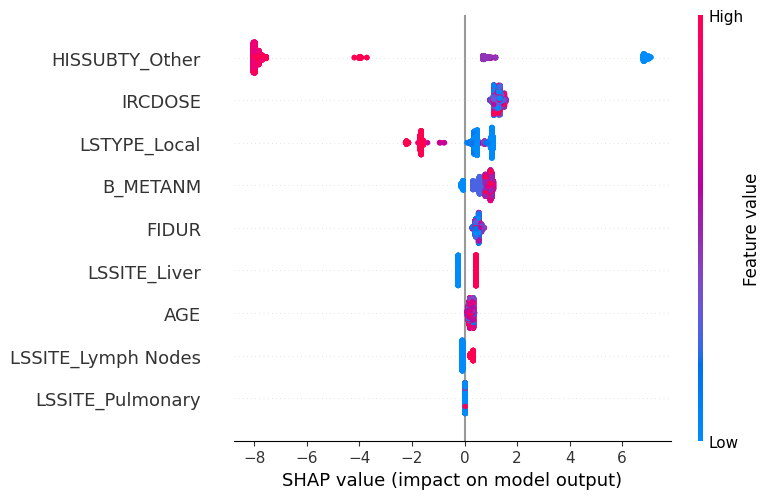

In [85]:
shap.summary_plot(shap_values, X_train)

In [86]:
shap_importance = np.abs(shap_values).mean(axis=0)
feature_importance = pd.DataFrame(list(zip(X_train.columns, shap_importance)), columns=['Feature', 'Importance'])

feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

print(feature_importance)


              Feature  Importance
8      HISSUBTY_Other    7.074007
6             IRCDOSE    1.286850
7        LSTYPE_Local    0.937065
4            B_METANM    0.723431
5               FIDUR    0.497900
0        LSSITE_Liver    0.324194
3                 AGE    0.249836
1  LSSITE_Lymph Nodes    0.114596
2    LSSITE_Pulmonary    0.021303


# load 1053 dataset

In [167]:
df_1053=pd.read_csv("C:\\Users\\Devesh\\Downloads\\NCT00115765 - 1053 (csv)-20240820T215820Z-001\\NCT00115765 - 1053 (csv)\\lesion.csv")

In [168]:
column_1053 = ['LSSITE' , 'LSTYPE', 'SUBJID' , 'AGE' , 'B_METANM' , 'LSSLD','LSCAT']
df_1053_f = df_1053[column_1053]

In [169]:
sendpt_df = pd.read_csv("C:\\Users\\Devesh\\Downloads\\NCT00115765 - 1053 (csv)-20240820T215820Z-001\\NCT00115765 - 1053 (csv)\\a_sendpt.csv")
col_send_1053 = ['FIDURWK' , 'IRCDOSE', 'SUBJID']
sendpt_df = sendpt_df[col_send_1053]
sendpt_df['FIDUR'] = sendpt_df['FIDURWK']
sendpt_df.drop(columns=['FIDURWK'],inplace=True)

In [170]:
df_1053_f.shape

(30153, 7)

In [171]:
sendpt_df.shape

(823, 3)

In [172]:
df_1053_f = pd.merge(df_1053_f,sendpt_df,on=['SUBJID'],how='left')

In [173]:
df_1053_f = df_1053_f[df_1053_f['LSCAT']=='Target lesion']

In [174]:
df_1053_f.shape

(16941, 9)

In [175]:
df_1053_f.drop(columns = ['IRCDOSE'],inplace=True)
df_1053_f = df_1053_f.dropna(subset=['LSSLD','LSSITE','FIDUR'])
df_1053_f = df_1053_f.reset_index(drop=True)

In [176]:
# Group by SUBJID and LSSITE, then apply the percentage change calculation
res_df_1053_f = df_1053_f.groupby(['SUBJID', 'LSSITE']).apply(calculate_percentage_change).reset_index(drop=True)

In [177]:
res_df_1053_f.shape

(1198, 8)

In [178]:
res_df_1053_f.isnull().sum()

LSSITE              0
LSTYPE              0
SUBJID              0
AGE                 0
B_METANM            0
LSCAT               0
FIDUR               0
LSSLD_PCT_CHANGE    0
dtype: int64

In [179]:
res_df_1053_f['LSSLD_Change'] = np.where(res_df_1053_f['LSSLD_PCT_CHANGE'] >= 30, 1, 0)

In [180]:
res_df_1053_f = pd.get_dummies(res_df_1053_f)

In [181]:
res_df_1053_f.head()

,SUBJID,AGE,B_METANM,FIDUR,LSSLD_PCT_CHANGE,LSSLD_Change,LSSITE_Abdomen,LSSITE_Bone,LSSITE_Cardiovascular,LSSITE_Gastrointestinal,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Rectal,LSSITE_Respiratory,LSSITE_Retroperitoneum,LSSITE_Skin,LSSITE_Spleen,LSTYPE_Central,LSCAT_Target lesion
0,249101001,67.0,1.0,99.714286,60.784314,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1
1,249101002,72.0,2.0,37.000000,25.602410,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1
2,249101002,72.0,2.0,37.000000,25.602410,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1
3,249101002,72.0,2.0,37.000000,25.602410,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,1
4,249101003,78.0,2.0,25.571429,30.088496,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1


In [183]:
res_df_1053_f.drop(columns=['LSSLD_PCT_CHANGE','LSSITE_Abdomen','LSSITE_Bone','LSSITE_Cardiovascular','LSSITE_Gastrointestinal','LSSITE_Other','LSSITE_Pelvic Site','LSSITE_Rectal','LSSITE_Respiratory'	,'LSSITE_Retroperitoneum','LSSITE_Skin','LSSITE_Spleen','LSTYPE_Central','LSCAT_Target lesion'],inplace=True)

In [184]:
res_df_1053_f['LSSLD_Change'].value_counts()

1    642
0    556
Name: LSSLD_Change, dtype: int64

In [185]:
res_df_1053_f.head()

,SUBJID,AGE,B_METANM,FIDUR,LSSLD_Change,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Pulmonary
0,249101001,67.0,1.0,99.714286,1,0,0,1
1,249101002,72.0,2.0,37.000000,0,1,0,0
2,249101002,72.0,2.0,37.000000,0,0,1,0
3,249101002,72.0,2.0,37.000000,0,0,0,0
4,249101003,78.0,2.0,25.571429,1,1,0,0


Synthetic data generation for 1053

In [186]:
common_all_fea = ['AGE' , 'B_METANM' , 'LSSITE_Liver','LSSITE_Lymph Nodes','LSSITE_Pulmonary','FIDUR','LSSLD_Change']

In [189]:
X_1186_1183 = df_final[common_all_fea]
y = df_final[['HISSUBTY_Other','IRCDOSE']]

In [208]:
X_1186_1183.head()

,AGE,B_METANM,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Pulmonary,FIDUR,LSSLD_Change
0,54.0,4.0,1,0,0,230.0,1
1,54.0,4.0,0,0,0,230.0,0
2,54.0,4.0,0,0,1,230.0,1
3,54.0,4.0,0,0,0,230.0,1
4,66.0,3.0,1,0,0,71.0,1


In [209]:
model_1186_1183 = xgb.XGBRegressor(objective='reg:squarederror')

grid_search_1186_1183  = GridSearchCV(estimator=model_1186_1183 , param_grid=param_grid, cv=3, n_jobs=-1, verbose=2)
grid_search_1186_1183.fit(X_1186_1183, y)

best_model_1186_1183  = grid_search_1186_1183.best_estimator_

Fitting 3 folds for each of 729 candidates, totalling 2187 fits


In [210]:
best_model_1186_1183

XGBRegressor(base_score=0.5, booster='gbtree', callbacks=None,
             colsample_bylevel=1, colsample_bynode=1, colsample_bytree=0.8,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, gamma=0.3, gpu_id=-1, grow_policy='depthwise',
             importance_type=None, interaction_constraints='',
             learning_rate=0.1, max_bin=256, max_cat_to_onehot=4,
             max_delta_step=0, max_depth=3, max_leaves=0, min_child_weight=1,
             missing=nan, monotone_constraints='()', n_estimators=100, n_jobs=0,
             num_parallel_tree=1, predictor='auto', random_state=0, reg_alpha=0,
             reg_lambda=1, ...)

In [211]:
X_1053 = res_df_1053_f[common_all_fea]

In [204]:
X_1053

,AGE,B_METANM,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Pulmonary,FIDUR,LSSLD_Change
0,67.0,1.0,0,0,1,99.714286,1
1,72.0,2.0,1,0,0,37.000000,0
2,72.0,2.0,0,1,0,37.000000,0
3,72.0,2.0,0,0,0,37.000000,0
4,78.0,2.0,1,0,0,25.571429,1
...,...,...,...,...,...,...,...
1193,79.0,3.0,0,0,0,5.714286,0
1194,79.0,3.0,1,0,0,5.714286,0
1195,79.0,3.0,0,0,1,5.714286,0
1196,70.0,2.0,0,0,0,14.000000,0


In [212]:
pred_1053 = best_model_1186_1183.predict(X_1053)

In [213]:
# Adding predictions to df_1053
res_df_1053_final = res_df_1053_f.copy()
res_df_1053_final[['HISSUBTY_Other', 'IRCDOSE']] = pred_1053

In [217]:
res_df_1053_final.drop_duplicates(inplace=True)

In [218]:
res_df_1053_final.shape

(1183, 10)

In [220]:
res_df_1053_final.head()

,SUBJID,AGE,B_METANM,FIDUR,LSSLD_Change,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Pulmonary,HISSUBTY_Other,IRCDOSE
0,249101001,67.0,1.0,99.714286,1,0,0,1,0.104516,2198.518555
1,249101002,72.0,2.0,37.000000,0,1,0,0,0.111875,542.645630
2,249101002,72.0,2.0,37.000000,0,0,1,0,0.111875,580.808044
3,249101002,72.0,2.0,37.000000,0,0,0,0,0.111875,574.532837
4,249101003,78.0,2.0,25.571429,1,1,0,0,0.104516,412.137634


In [222]:
df_all = pd.concat([df_final, res_df_1053_final], axis=0)
df_all.reset_index(drop=True, inplace=True)

# 1053_1186_1183 combined model builduing

In [226]:
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from scipy.stats import randint, uniform

In [224]:
df_all.drop(columns=['SUBJID'],inplace=True)

In [225]:
X = df_all.drop(columns=['LSSLD_Change'])
y = df_all['LSSLD_Change']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [227]:
xgb_param_grid = {
    'n_estimators': randint(50, 500),
    'max_depth': randint(3, 10),
    'learning_rate': uniform(0.01, 0.1),
    'subsample': uniform(0.6, 0.9),
    'colsample_bytree': uniform(0.6, 0.9)
}

In [228]:
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb_random = RandomizedSearchCV(estimator=xgb, param_distributions=xgb_param_grid, 
                                n_iter=50, cv=5, verbose=1, random_state=42, n_jobs=-1)

xgb_random.fit(X_train_scaled, y_train)

xgb_best = xgb_random.best_estimator_

Fitting 5 folds for each of 50 candidates, totalling 250 fits


In [229]:
print("XGBoost Classification Report:")
print(classification_report(y_test, xgb_best.predict(X_test_scaled)))

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       167
           1       1.00      1.00      1.00       310

    accuracy                           1.00       477
   macro avg       1.00      1.00      1.00       477
weighted avg       1.00      1.00      1.00       477



In [230]:
feature_importance_combined = pd.DataFrame({'feature': X.columns, 'importance': xgb_best.feature_importances_})
feature_importance_combined = feature_importance_combined.sort_values('importance', ascending=False)

print("Top feature importance for partial responce in non target lesions are:")
print(feature_importance_combined)

Top feature importance for partial responce in non target lesions are:
              feature  importance
8      HISSUBTY_Other    0.353560
0        LSSITE_Liver    0.212288
7        LSTYPE_Local    0.093379
2    LSSITE_Pulmonary    0.088462
6             IRCDOSE    0.087258
5               FIDUR    0.056848
1  LSSITE_Lymph Nodes    0.047029
4            B_METANM    0.036239
3                 AGE    0.024936


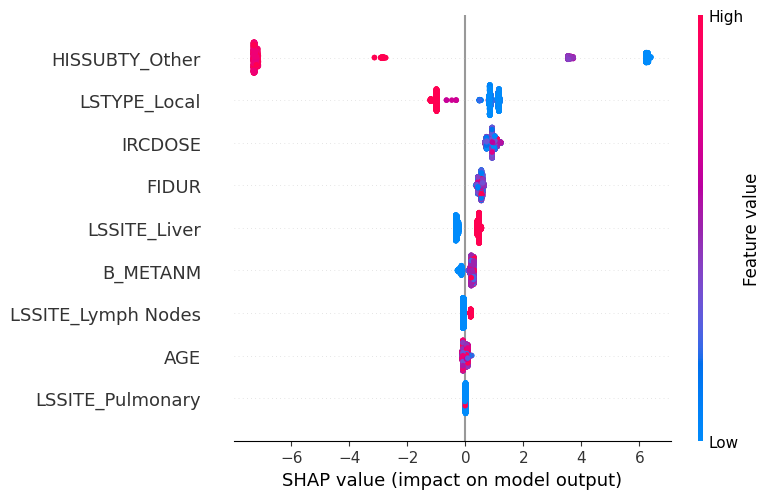

In [232]:
import shap
explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer.shap_values(X_train)
shap.summary_plot(shap_values, X_train)